ПРАКТИЧЕСКАЯ РАБОТА №9
КЛАССИФИКАЦИЯ

ЗАДАНИЕ 1: Weather Type Classification
Файл загружен. Форма: (13200, 11)

Первые 5 строк:
   Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
0         14.0        73         9.5               82.0  partly cloudy   
1         39.0        96         8.5               71.0  partly cloudy   
2         30.0        64         7.0               16.0          clear   
3         38.0        83         1.5               82.0          clear   
4         27.0        74        17.0               66.0       overcast   

   Atmospheric Pressure  UV Index  Season  Visibility (km)  Location  \
0               1010.82         2  Winter              3.5    inland   
1               1011.43         7  Spring             10.0    inland   
2               1018.72         5  Spring              5.5  mountain   
3               1026.25         7  Spring              1.0   coastal   
4                990.67         1  Winter              2.5  mountai

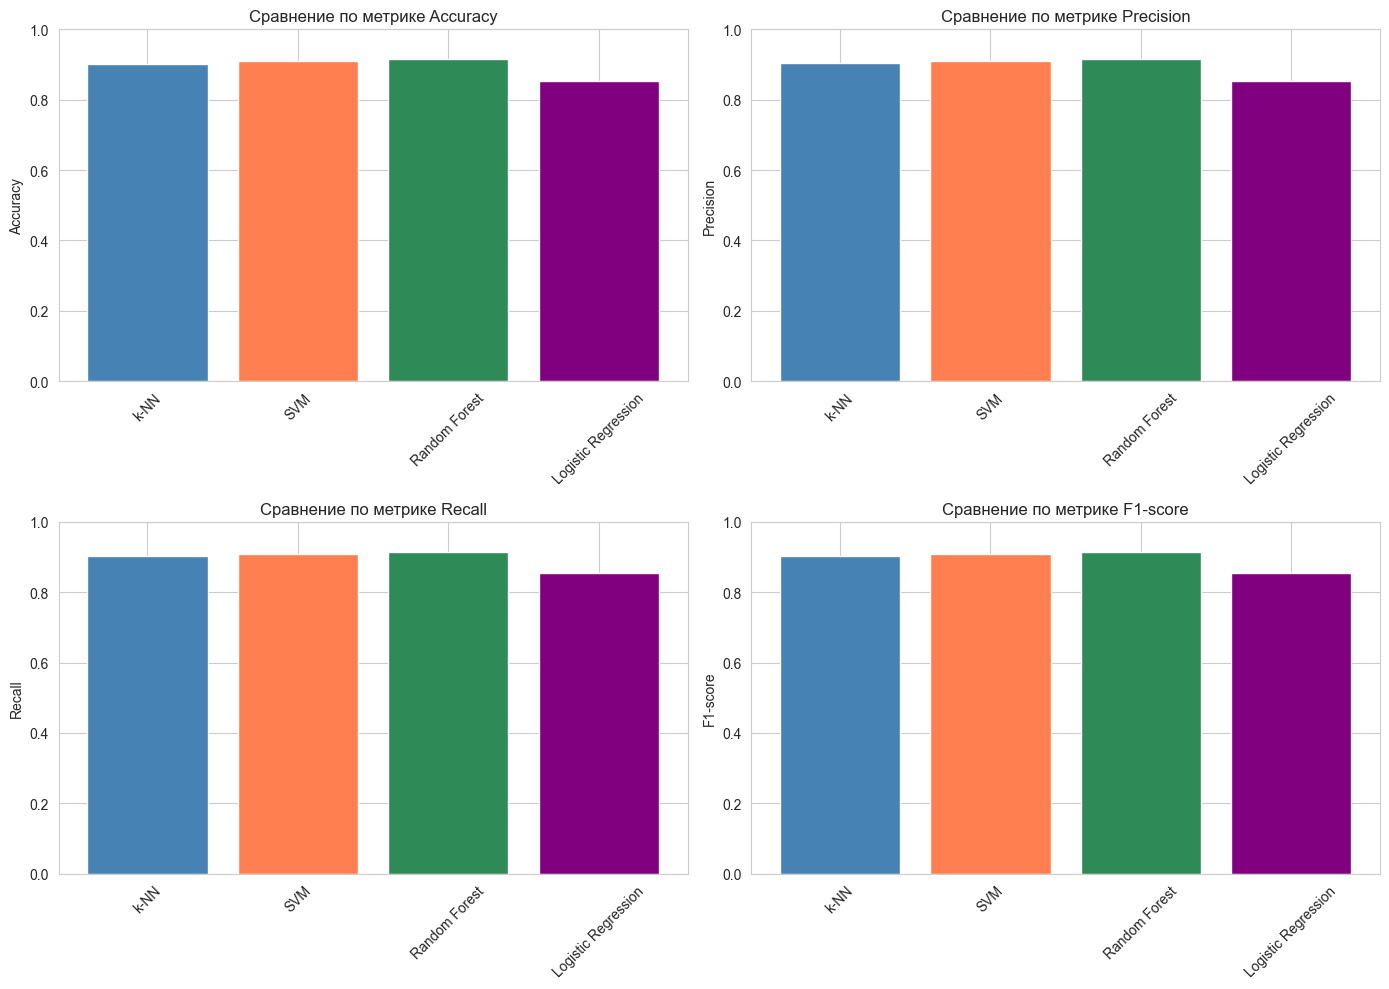


Лучшая модель: Random Forest


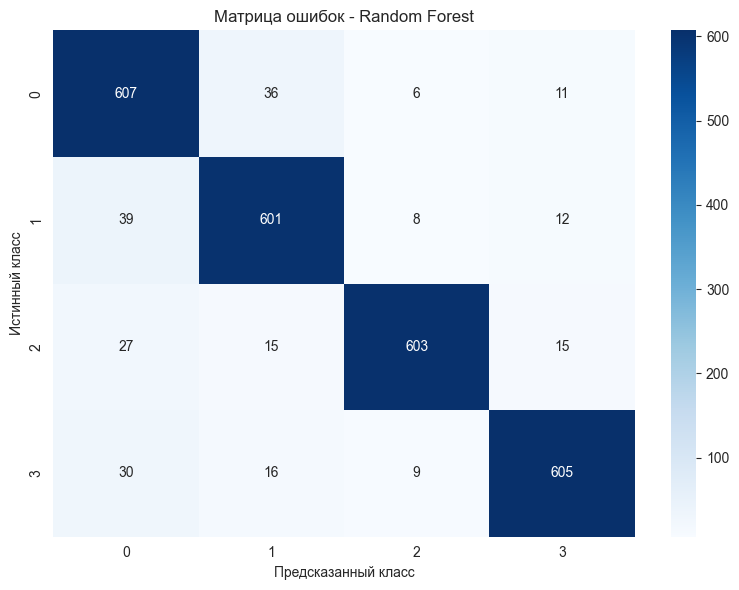


ЗАДАНИЕ *: Улучшение точности модели для Clothes Size Prediction
Файл загружен. Форма: (119734, 4)

Первые 5 строк:
   weight   age  height size
0      62  28.0  172.72   XL
1      59  36.0  167.64    L
2      61  34.0  165.10    M
3      65  27.0  175.26    L
4      62  45.0  172.72    M

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119734 entries, 0 to 119733
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   weight  119734 non-null  int64  
 1   age     119477 non-null  float64
 2   height  119404 non-null  float64
 3   size    119734 non-null  object 
dtypes: float64(2), int64(1), object(1)
memory usage: 3.7+ MB

Пропуски в данных ДО очистки:
weight      0
age       257
height    330
size        0
dtype: int64
  Пропуски в age заполнены медианой: 32.0
  Пропуски в height заполнены медианой: 165.1

Пропуски в данных ПОСЛЕ очистки:
0

Кодирование размера: {'S': 0, 'M': 1, 'L': 2, 'XL': 3, 'XXL': 

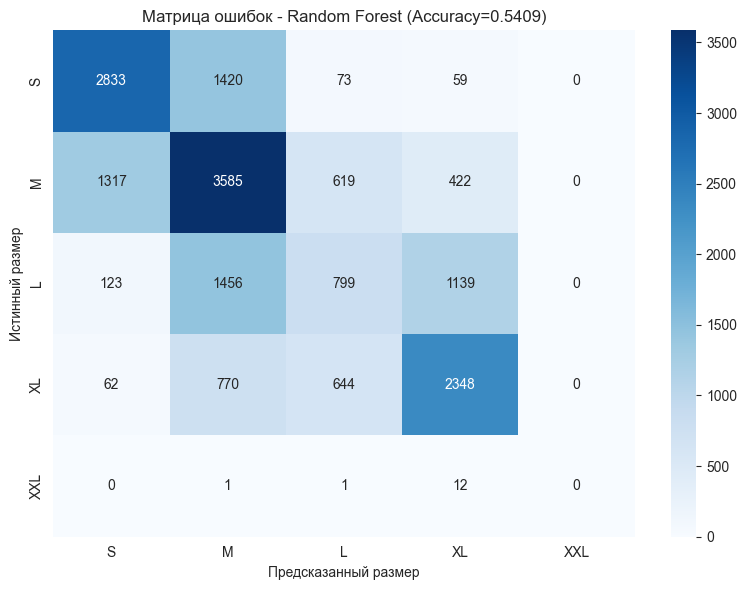


Classification Report:
              precision    recall  f1-score   support

           S       0.65      0.65      0.65      4385
           M       0.50      0.60      0.54      5943
           L       0.37      0.23      0.28      3517
          XL       0.59      0.61      0.60      3824
         XXL       0.00      0.00      0.00        14

    accuracy                           0.54     17683
   macro avg       0.42      0.42      0.42     17683
weighted avg       0.53      0.54      0.53     17683


Важность признаков:
               feature  importance
0               weight    0.279891
4       weight_squared    0.249542
6  weight_height_ratio    0.248723
1                  age    0.119233
3                  bmi    0.067281
5       height_squared    0.021634
2               height    0.013697


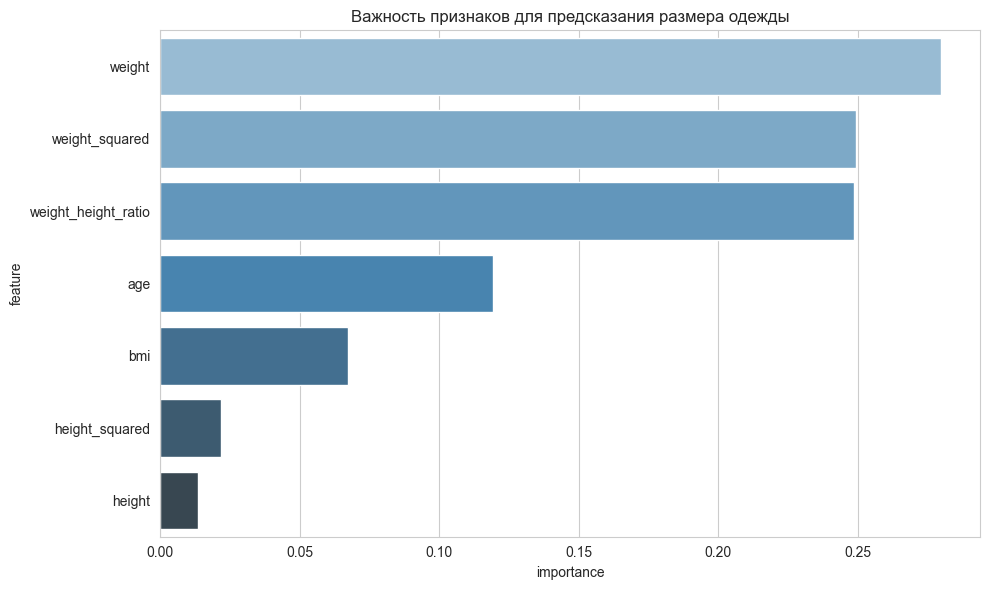


ИТОГОВЫЕ ВЫВОДЫ

Задание 1 (Weather Type Classification):
  - k-NN: Accuracy=0.9023, F1=0.9029
  - SVM: Accuracy=0.9087, F1=0.9090
  - Random Forest: Accuracy=0.9152, F1=0.9156
  - Logistic Regression: Accuracy=0.8538, F1=0.8537
  - Лучшая модель: Random Forest

Задание * (Clothes Size Prediction):
  - Точность Random Forest после оптимизации: 0.5409
  - Цель (accuracy >= 0.7): Не достигнута
  - Ключевые признаки: weight, weight_squared, weight_height_ratio



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("ПРАКТИЧЕСКАЯ РАБОТА №9")
print("КЛАССИФИКАЦИЯ")
print("="*60)

# ============================================================
# ЗАДАНИЕ 1
# ============================================================

print("\n" + "="*60)
print("ЗАДАНИЕ 1: Weather Type Classification")
print("="*60)

WEATHER_FILE = "data/weather_classification_data.csv"

try:
    df_weather = pd.read_csv(WEATHER_FILE)
    print(f"Файл загружен. Форма: {df_weather.shape}")
    print("\nПервые 5 строк:")
    print(df_weather.head())
except FileNotFoundError:
    print(f"Ошибка: файл '{WEATHER_FILE}' не найден")
    exit(1)
except Exception as e:
    print(f"Ошибка загрузки: {e}")
    exit(1)

print("\nИнформация о данных:")
df_weather.info()

print("\nОписательная статистика:")
print(df_weather.describe())

# Проверка пропусков
print("\nПропуски в данных:")
print(df_weather.isnull().sum())

# Кодирование категориальных признаков
categorical_cols = ['Cloud Cover', 'Season', 'Location']
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df_weather[col + '_encoded'] = le.fit_transform(df_weather[col])
    label_encoders[col] = le
    print(f"\n{col} - уникальные значения: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Кодирование целевой переменной
target_le = LabelEncoder()
df_weather['Weather_Type_encoded'] = target_le.fit_transform(df_weather['Weather Type'])
print(f"\nWeather Type - уникальные значения: {dict(zip(target_le.classes_, target_le.transform(target_le.classes_)))}")

# Отбор признаков (используем закодированные версии)
feature_cols = ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)',
                'Atmospheric Pressure', 'UV Index', 'Visibility (km)',
                'Cloud Cover_encoded', 'Season_encoded', 'Location_encoded']

X = df_weather[feature_cols]
y = df_weather['Weather_Type_encoded']

# Нормализация числовых признаков
numeric_cols = ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)',
                'Atmospheric Pressure', 'UV Index', 'Visibility (km)']

scaler = StandardScaler()
X_numeric_scaled = scaler.fit_transform(X[numeric_cols])

# Объединяем нормализованные числовые и закодированные категориальные
encoded_cols = ['Cloud Cover_encoded', 'Season_encoded', 'Location_encoded']
X_scaled = np.hstack([X_numeric_scaled, X[encoded_cols].values])

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nРазмер обучающей выборки: {X_train.shape[0]}")
print(f"Размер тестовой выборки: {X_test.shape[0]}")
print(f"Распределение классов в обучающей выборке:\n{y_train.value_counts().sort_index().to_dict()}")
print(f"Распределение классов в тестовой выборке:\n{y_test.value_counts().sort_index().to_dict()}")

# ============================================================
# 2. ПОСТРОЕНИЕ МОДЕЛЕЙ КЛАССИФИКАЦИИ
# ============================================================

print("\n" + "="*60)
print("ПОСТРОЕНИЕ МОДЕЛЕЙ КЛАССИФИКАЦИИ")
print("="*60)

results = []

# 1. K-Nearest Neighbors (k-NN)
print("\n1. Модель: K-Nearest Neighbors (k-NN)")

# Поиск лучшего k
k_values = range(1, 21)
knn_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    knn_scores.append(accuracy_score(y_test, y_pred))

best_k = k_values[np.argmax(knn_scores)]
print(f"  Лучшее k: {best_k}")

# Обучение с лучшим k
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train, y_train)
y_pred_knn = knn_best.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, average='weighted')
recall_knn = recall_score(y_test, y_pred_knn, average='weighted')
f1_knn = f1_score(y_test, y_pred_knn, average='weighted')

print(f"  Accuracy: {accuracy_knn:.4f}")
print(f"  Precision: {precision_knn:.4f}")
print(f"  Recall: {recall_knn:.4f}")
print(f"  F1-score: {f1_knn:.4f}")

results.append({
    'Model': 'k-NN',
    'Accuracy': accuracy_knn,
    'Precision': precision_knn,
    'Recall': recall_knn,
    'F1-score': f1_knn
})

# 2. Support Vector Machine (SVM)
print("\n2. Модель: Support Vector Machine (SVM)")

# Поиск лучших параметров
svm_params = {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}
svm = SVC(random_state=42)
svm_grid = GridSearchCV(svm, svm_params, cv=5, scoring='accuracy')
svm_grid.fit(X_train, y_train)

print(f"  Лучшие параметры: {svm_grid.best_params_}")
svm_best = svm_grid.best_estimator_
y_pred_svm = svm_best.predict(X_test)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, average='weighted')
recall_svm = recall_score(y_test, y_pred_svm, average='weighted')
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')

print(f"  Accuracy: {accuracy_svm:.4f}")
print(f"  Precision: {precision_svm:.4f}")
print(f"  Recall: {recall_svm:.4f}")
print(f"  F1-score: {f1_svm:.4f}")

results.append({
    'Model': 'SVM',
    'Accuracy': accuracy_svm,
    'Precision': precision_svm,
    'Recall': recall_svm,
    'F1-score': f1_svm
})

# 3. Random Forest
print("\n3. Модель: Random Forest")

# Поиск лучших параметров
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}
rf = RandomForestClassifier(random_state=42)
rf_grid = GridSearchCV(rf, rf_params, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train, y_train)

print(f"  Лучшие параметры: {rf_grid.best_params_}")
rf_best = rf_grid.best_estimator_
y_pred_rf = rf_best.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='weighted')
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

print(f"  Accuracy: {accuracy_rf:.4f}")
print(f"  Precision: {precision_rf:.4f}")
print(f"  Recall: {recall_rf:.4f}")
print(f"  F1-score: {f1_rf:.4f}")

results.append({
    'Model': 'Random Forest',
    'Accuracy': accuracy_rf,
    'Precision': precision_rf,
    'Recall': recall_rf,
    'F1-score': f1_rf
})

# 4. Логистическая регрессия (дополнительно)
print("\n4. Модель: Логистическая регрессия")

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, average='weighted')
recall_lr = recall_score(y_test, y_pred_lr, average='weighted')
f1_lr = f1_score(y_test, y_pred_lr, average='weighted')

print(f"  Accuracy: {accuracy_lr:.4f}")
print(f"  Precision: {precision_lr:.4f}")
print(f"  Recall: {recall_lr:.4f}")
print(f"  F1-score: {f1_lr:.4f}")

results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_lr,
    'Precision': precision_lr,
    'Recall': recall_lr,
    'F1-score': f1_lr
})

# ============================================================
# 3. СРАВНЕНИЕ МОДЕЛЕЙ
# ============================================================

print("\n" + "="*60)
print("СРАВНЕНИЕ МОДЕЛЕЙ")
print("="*60)

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# Визуализация сравнения
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
for i, metric in enumerate(metrics):
    row, col = i // 2, i % 2
    axes[row, col].bar(results_df['Model'], results_df[metric], color=['steelblue', 'coral', 'seagreen', 'purple'])
    axes[row, col].set_title(f'Сравнение по метрике {metric}')
    axes[row, col].set_ylim(0, 1)
    axes[row, col].set_ylabel(metric)
    axes[row, col].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Матрицы ошибок для лучшей модели
best_model_name = results_df.loc[results_df['Accuracy'].idxmax(), 'Model']
print(f"\nЛучшая модель: {best_model_name}")

if best_model_name == 'k-NN':
    best_y_pred = y_pred_knn
elif best_model_name == 'SVM':
    best_y_pred = y_pred_svm
elif best_model_name == 'Random Forest':
    best_y_pred = y_pred_rf
else:
    best_y_pred = y_pred_lr

cm = confusion_matrix(y_test, best_y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Матрица ошибок - {best_model_name}')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.show()

# ============================================================
# ЗАДАНИЕ *
# ============================================================

print("\n" + "="*60)
print("ЗАДАНИЕ *: Улучшение точности модели для Clothes Size Prediction")
print("="*60)

CLOTHES_FILE = "data/final_test.csv"

try:
    df_clothes = pd.read_csv(CLOTHES_FILE)
    print(f"Файл загружен. Форма: {df_clothes.shape}")
    print("\nПервые 5 строк:")
    print(df_clothes.head())
except FileNotFoundError:
    print(f"Ошибка: файл '{CLOTHES_FILE}' не найден")
    exit(1)
except Exception as e:
    print(f"Ошибка загрузки: {e}")
    exit(1)

print("\nИнформация о данных:")
df_clothes.info()

print("\nПропуски в данных ДО очистки:")
print(df_clothes.isnull().sum())

# Обработка пропусков
for col in df_clothes.columns:
    if df_clothes[col].isna().sum() > 0:
        if pd.api.types.is_numeric_dtype(df_clothes[col]):
            df_clothes[col] = df_clothes[col].fillna(df_clothes[col].median())
            print(f"  Пропуски в {col} заполнены медианой: {df_clothes[col].median()}")
        else:
            mode_val = df_clothes[col].mode()[0]
            df_clothes[col] = df_clothes[col].fillna(mode_val)
            print(f"  Пропуски в {col} заполнены модой: {mode_val}")

print("\nПропуски в данных ПОСЛЕ очистки:")
print(df_clothes.isnull().sum().sum())

# Создание новых признаков (feature engineering)
df_clothes['bmi'] = df_clothes['weight'] / (df_clothes['height'] / 100) ** 2
df_clothes['weight_squared'] = df_clothes['weight'] ** 2
df_clothes['height_squared'] = df_clothes['height'] ** 2
df_clothes['weight_height_ratio'] = df_clothes['weight'] / df_clothes['height']

# Кодирование целевой переменной
size_order = ['S', 'M', 'L', 'XL', 'XXL']
size_to_num = {size: i for i, size in enumerate(size_order)}
df_clothes['size_encoded'] = df_clothes['size'].map(size_to_num)

# Удаляем строки с NaN в целевой переменной (если есть)
df_clothes = df_clothes.dropna(subset=['size_encoded'])

print(f"\nКодирование размера: {size_to_num}")
print(f"Размер после очистки: {df_clothes.shape}")

# Отбор признаков
feature_cols_clothes = ['weight', 'age', 'height', 'bmi', 'weight_squared', 'height_squared', 'weight_height_ratio']
X_clothes = df_clothes[feature_cols_clothes]
y_clothes = df_clothes['size_encoded']

# Проверка на NaN в X и y
print(f"\nПроверка на NaN в X: {X_clothes.isnull().sum().sum()}")
print(f"Проверка на NaN в y: {y_clothes.isnull().sum()}")

# Нормализация
scaler_clothes = StandardScaler()
X_clothes_scaled = scaler_clothes.fit_transform(X_clothes)

# Разделение на train/test (без stratify, если мало данных)
try:
    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        X_clothes_scaled, y_clothes, test_size=0.2, random_state=42, stratify=y_clothes
    )
except ValueError:
    print("Предупреждение: stratify не работает из-за малого количества данных, используем без stratify")
    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        X_clothes_scaled, y_clothes, test_size=0.2, random_state=42
    )

print(f"\nРазмер обучающей выборки: {X_train_c.shape[0]}")
print(f"Размер тестовой выборки: {X_test_c.shape[0]}")
print(f"Распределение классов в обучающей выборке:\n{pd.Series(y_train_c).value_counts().sort_index().to_dict()}")
print(f"Распределение классов в тестовой выборке:\n{pd.Series(y_test_c).value_counts().sort_index().to_dict()}")

# Поиск лучшей модели с GridSearchCV
print("\nПоиск лучших параметров для Random Forest...")

rf_clothes = RandomForestClassifier(random_state=42)
param_grid_clothes = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_clothes = GridSearchCV(rf_clothes, param_grid_clothes, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_clothes.fit(X_train_c, y_train_c)

print(f"\nЛучшие параметры: {grid_clothes.best_params_}")
best_rf_clothes = grid_clothes.best_estimator_
y_pred_c = best_rf_clothes.predict(X_test_c)

accuracy_c = accuracy_score(y_test_c, y_pred_c)
print(f"\nТочность модели: {accuracy_c:.4f}")

if accuracy_c >= 0.7:
    print("Результат: Цель достигнута! Точность >= 0.7")
else:
    print(f"Результат: Точность {accuracy_c:.4f} < 0.7. Требуется дальнейшая настройка")

# Матрица ошибок
cm_c = confusion_matrix(y_test_c, y_pred_c)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_c, annot=True, fmt='d', cmap='Blues',
            xticklabels=size_order, yticklabels=size_order)
plt.title(f'Матрица ошибок - Random Forest (Accuracy={accuracy_c:.4f})')
plt.xlabel('Предсказанный размер')
plt.ylabel('Истинный размер')
plt.tight_layout()
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_c, target_names=size_order))

# Важность признаков
feature_importance = pd.DataFrame({
    'feature': feature_cols_clothes,
    'importance': best_rf_clothes.feature_importances_
}).sort_values('importance', ascending=False)

print("\nВажность признаков:")
print(feature_importance)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='importance', y='feature', palette='Blues_d')
plt.title('Важность признаков для предсказания размера одежды')
plt.tight_layout()
plt.show()

# ============================================================
# ИТОГОВЫЕ ВЫВОДЫ
# ============================================================

print("\n" + "="*60)
print("ИТОГОВЫЕ ВЫВОДЫ")
print("="*60)

print("\nЗадание 1 (Weather Type Classification):")
print(f"  - k-NN: Accuracy={accuracy_knn:.4f}, F1={f1_knn:.4f}")
print(f"  - SVM: Accuracy={accuracy_svm:.4f}, F1={f1_svm:.4f}")
print(f"  - Random Forest: Accuracy={accuracy_rf:.4f}, F1={f1_rf:.4f}")
print(f"  - Logistic Regression: Accuracy={accuracy_lr:.4f}, F1={f1_lr:.4f}")
print(f"  - Лучшая модель: {best_model_name}")

print("\nЗадание * (Clothes Size Prediction):")
print(f"  - Точность Random Forest после оптимизации: {accuracy_c:.4f}")
print(f"  - Цель (accuracy >= 0.7): {'Достигнута' if accuracy_c >= 0.7 else 'Не достигнута'}")
print(f"  - Ключевые признаки: {', '.join(feature_importance['feature'].head(3).tolist())}")

print("\n" + "="*60)